# Лабораторная работа №2

ФИО: Тихонов Дмитрий Вячеславович
Группа: БИВТ-24-СП-4



Исходные данные:
файл data/StudentsPerformance.csv


## 0. Импорт библиотек и данных

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# настройки графиков: размер, сетка, читаемый шрифт
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['figure.dpi'] = 100

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print('Библиотеки загружены')

Библиотеки загружены


In [2]:
from pathlib import Path

DATASET_NAME = 'StudentsPerformance.csv'


# Ноутбук лежит в src/, а датасет — в data/, поэтому путь нельзя задавать
# относительно текущей директории: при запуске из корня репозитория и из src/
# он получится разным. Поэтому сначала находим корень проекта, а уже от него
# строим путь к данным.
def find_project_root(start):
    """Корень проекта — ближайшая папка вверх по дереву, где есть src/ и data/."""
    for candidate in [start, *start.parents]:
        if (candidate / 'src').is_dir() and (candidate / 'data').is_dir():
            return candidate
    return start


def find_dataset(filename, start=None):
    """Ищет файл данных в типовых местах структуры репозитория."""
    start = Path.cwd() if start is None else Path(start)
    root = find_project_root(start)

    candidates = [
        root / 'data' / filename,           # <repo>/data/<файл> — основной вариант
        root / filename,                    # <repo>/<файл>
        start / filename,                   # файл рядом с ноутбуком
        start / 'data' / filename,
        start.parent / 'data' / filename,   # ../data, если корень не определился
        start.parent / filename,
    ]
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()

    # резервный вариант — рекурсивный поиск внутри проекта
    for folder in (root / 'data', root):
        if folder.is_dir():
            for found in sorted(folder.rglob(filename)):
                return found.resolve()

    # последний шанс: файл могли сохранить под другим именем — берём
    # единственный CSV из data/, но обязательно предупреждаем об этом
    data_dir = root / 'data'
    if data_dir.is_dir():
        csv_files = sorted(data_dir.glob('*.csv'))
        if len(csv_files) == 1:
            print(f'ВНИМАНИЕ: файл {filename} не найден, использую {csv_files[0].name}')
            return csv_files[0].resolve()

    raise FileNotFoundError(
        f"Не найден файл '{filename}'.\n"
        f"Текущая директория: {start}\n"
        f"Корень проекта:     {root}\n"
        f"Ожидаемый путь:     {root / 'data' / filename}\n"
        f"Положите датасет в папку data/ и запустите ноутбук из src/ "
        f"или из корня репозитория."
    )


path_to_dataset = find_dataset(DATASET_NAME)
print(f'Датасет найден: {path_to_dataset}')

# разделитель в файле — запятая, поэтому sep не нужен;
# utf-8-sig заодно снимает BOM, который появляется у CSV, сохранённых в Excel
data = pd.read_csv(path_to_dataset, encoding='utf-8-sig')
print(f'Загружено: {data.shape[0]} строк, {data.shape[1]} колонок')
data.head()

Датасет найден: C:\Users\User\Desktop\labs_ai\data\StudentsPerformance.csv
Загружено: 1000 строк, 8 колонок


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 1. Название датасета

По таблице с вариантами моему варианту соответствует датасет **«Students Performance in Exams»** — файл `StudentsPerformance.csv` (данные об успеваемости 1000 школьников на экзаменах по трём предметам).

Ниже — размер датасета и первые строки, чтобы зафиксировать, с чем работаем.

In [3]:
print(f'Размер датасета: {data.shape[0]} строк, {data.shape[1]} колонок')
print(f'Колонки: {list(data.columns)}')

Размер датасета: 1000 строк, 8 колонок
Колонки: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


## 2. Описание постановки задачи

**Постановка задачи.** Есть результаты экзаменов школьников вместе с их социально-демографическими характеристиками. Требуется проанализировать, от чего зависит успеваемость, и оценить, насколько признаки пригодны для прогнозирования баллов. В терминах машинного обучения это задача **регрессии**: по вектору признаков `X` предсказываем балл по математике.

**Целевая переменная:** `math score` — балл за экзамен по математике.
Формально это **дискретная** переменная: она принимает конечное множество целочисленных значений из отрезка `[0; 100]` (ровно 81 различное значение). При этом значений много и они упорядочены, поэтому по смыслу задача ближе к непрерывной регрессии, чем к классификации; дискретность здесь — следствие того, что балл округлён до целого.

**Признаки (`X`):**

| Признак | Тип | Описание |
|---|---|---|
| `gender` | категориальный (2) | пол учащегося |
| `race/ethnicity` | категориальный (5) | группа, к которой относится учащийся (A–E) |
| `parental level of education` | категориальный (6) | уровень образования родителей |
| `lunch` | категориальный (2) | тип питания: `standard` (платное) / `free/reduced` (бесплатное/льготное) — косвенный индикатор достатка семьи |
| `test preparation course` | категориальный (2) | проходил ли учащийся подготовительный курс |
| `reading score` | числовой, 17–100 | балл по чтению |
| `writing score` | числовой, 10–100 | балл по письму |

Важная деталь: `reading score` и `writing score` — это **другие экзаменационные баллы того же ученика**. Они сильно коррелируют с целевой переменной, но в реальной задаче прогнозирования «до экзамена» они были бы недоступны (утечка данных / data leakage). Поэтому в анализе взаимосвязей ниже я опираюсь в первую очередь на пять социально-демографических признаков, а баллы по чтению и письму рассматриваю отдельно — как вспомогательные.

## 3. Распределение целевой переменной

In [4]:
target = 'math score'

print(f'Количество уникальных значений целевой переменной: {data[target].nunique()}')
print(f'Минимум: {data[target].min()}, максимум: {data[target].max()}')
print(f'Среднее: {data[target].mean():.2f}, медиана: {data[target].median():.0f}, мода: {data[target].mode()[0]}')
print(f'Асимметрия (skew): {data[target].skew():.3f}, эксцесс (kurt): {data[target].kurt():.3f}')

Количество уникальных значений целевой переменной: 81
Минимум: 0, максимум: 100
Среднее: 66.09, медиана: 66, мода: 65
Асимметрия (skew): -0.279, эксцесс (kurt): 0.275


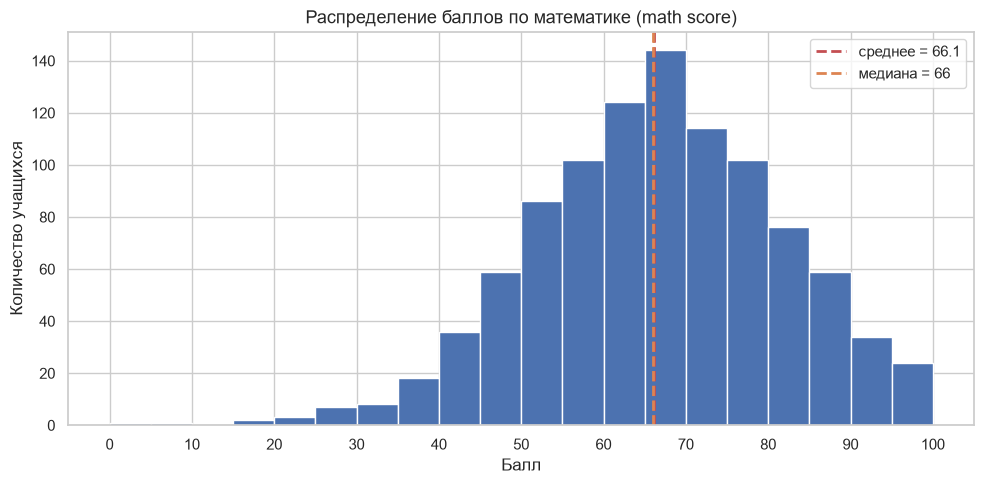

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(data[target], bins=range(0, 105, 5), color='#4C72B0', edgecolor='white')
ax.axvline(data[target].mean(), color='#C44E52', linestyle='--', linewidth=2,
           label=f'среднее = {data[target].mean():.1f}')
ax.axvline(data[target].median(), color='#DD8452', linestyle='--', linewidth=2,
           label=f'медиана = {data[target].median():.0f}')

ax.set_title('Распределение баллов по математике (math score)', fontsize=13)
ax.set_xlabel('Балл')
ax.set_ylabel('Количество учащихся')
ax.set_xticks(range(0, 101, 10))
ax.legend()
plt.tight_layout()
plt.show()

**Промежуточные выводы по распределению:**

- Распределение **однородное (унимодальное)**, без второго горба и без явных кластеров — похоже на слегка скошенное нормальное. Асимметрия `-0.28` — небольшой скос **влево**: хвост тянется в сторону низких баллов, а основная масса смещена вправо от центра (медиана 66 при среднем 66.1, мода 65).
- Центр распределения — около **66 баллов**, стандартное отклонение **15.2**. Межквартильный размах 57–77, то есть половина учеников укладывается в 20-балльный интервал.
- **Дисбаланса классов нет** в привычном смысле (это регрессия), но есть перекос по краям: высоких баллов (`>= 90`) всего **5.8%**, а низких (`<= 40`) — **5.0%**. Крайние значения представлены слабо, поэтому модель будет хуже предсказывать именно хвосты.
- Видимых артефактов почти нет, но есть **одна аномальная строка с `math score = 0`** при `reading = 17` и `writing = 10`. Это не пропуск, а реальное (либо ошибочно внесённое) значение; такие точки стоит проверить отдельно — они сильно тянут вниз статистики хвоста.
- Есть «потолок» на 100 баллах: `7` учеников получили ровно 100. Шкала ограничена сверху, что дополнительно прижимает правый хвост.

In [6]:
print(data[target].value_counts().sort_index().to_frame('count').T.to_string())

math score  0    8    18   19   22   23   24   26   27   28   29   30   32   33   34   35   36   37   38   39   40   41   42   43   44   45   46   47   48   49   50   51   52   53   54   55   56   57   58   59   60   61   62   63   64   65   66   67   68   69   70   71   72   73   74   75   76   77   78   79   80   81   82   83   84   85   86   87   88   89   90   91   92   93   94   95   96   97   98   99   100
count         1    1    1    1    1    1    1    1    2    1    3    2    3    1    2    5    2    4    3    4   10    6    6    5    9    9   11   11   11   17   15   11   18   24   18   18    9   18   25   32   16   27   35   26   20   36   24   26   26   32   18   26   18   27   25   21   21   24   14   22   17   22   18    8   11   14    8   16   15    6    8    9    6    4    7    2    3    6    3    3    7


## 4. Основные статистики по переменным

Один метод — `DataFrame.describe()`.

In [7]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.089,15.163080,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.169,14.600192,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


In [8]:
# тот же метод, но с явным указанием категориальных колонок:
# для них считаются count / unique / top / freq вместо квантилей
data.describe(include='object').T

,count,unique,top,freq
gender,1000,2,female,518
race/ethnicity,1000,5,group C,319
parental level of education,1000,6,some college,226
lunch,1000,2,standard,645
test preparation course,1000,2,none,642


**Что видно из статистик:**

- Все три балла живут в диапазоне примерно 0–100, средние близки: математика 66.1, чтение 69.2, письмо 68.1. То есть **математика даётся ученикам в среднем чуть тяжелее** остальных предметов.
- Стандартные отклонения почти одинаковые (14.6–15.2), значит разброс успеваемости по предметам сопоставим.
- Медианы (66 / 70 / 69) немного выше средних — подтверждение лёгкого левостороннего скоса.
- По категориальным: самая частая группа — `race/ethnicity = group C` (319 из 1000), самый частый уровень образования родителей — `some college` (226), платное питание у 645 учеников, подготовительные курсы проходили только 358.

## 5. Общая информация по датасету

Один метод — `DataFrame.info()`.

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


**Вывод:** в датасете **8 колонок**: 5 категориальных (`object`) и 3 числовых (`int64`). Все колонки содержат по **1000 non-null** значений, то есть по этому методу пропусков не видно. Память — около 62 КБ, данные целиком помещаются в память. Отдельного индекса-идентификатора нет, дубликатов строк — 0 (`data.duplicated().sum()`).

## 6. Пропуски в данных

In [10]:
missing = data.isna().sum()
missing_report = pd.DataFrame({
    'пропусков': missing,
    'доля, %': (missing / len(data) * 100).round(2)
})
print(missing_report)
print(f'\nВсего пропусков в датасете: {int(missing.sum())}')

                             пропусков  доля, %
gender                               0      0.0
race/ethnicity                       0      0.0
parental level of education          0      0.0
lunch                                0      0.0
test preparation course              0      0.0
math score                           0      0.0
reading score                        0      0.0
writing score                        0      0.0

Всего пропусков в датасете: 0


In [11]:
# на всякий случай проверим и другие представления «пустоты»,
# которые pandas не считает NaN автоматически
EMPTY_MARKERS = {'', 'na', 'n/a', 'nan', 'null', 'none', '-', '?', 'unknown', 'нет данных'}

# у категориальных признаков бывают легитимные значения, совпадающие
# с типовыми маркерами пустоты: 'none' в test preparation course означает
# «курс не проходил», а не пропуск. Такие значения из проверки исключаем,
# иначе получаем 642 ложных срабатывания.
VALID_CATEGORIES = {
    'test preparation course': {'none'},
}

suspicious_total = 0
for col in data.select_dtypes(include='object').columns:
    normalized = data[col].astype(str).str.strip().str.lower()
    markers = EMPTY_MARKERS - VALID_CATEGORIES.get(col, set())
    odd = normalized.isin(markers)
    suspicious_total += int(odd.sum())
    if odd.sum():
        found = sorted(normalized[odd].unique())
        print(f'{col}: {odd.sum()} подозрительных значений -> {found}')

if suspicious_total == 0:
    print('Строк, замаскированных под пустоту ("" / NA / null / "-" / "?"), не найдено')

print('Дубликатов строк:', data.duplicated().sum())
print('Полных дублей по всем колонкам:', data.duplicated(keep=False).sum())

Строк, замаскированных под пустоту ("" / NA / null / "-" / "?"), не найдено
Дубликатов строк: 0
Полных дублей по всем колонкам: 0


**Вывод по пропускам:** их **нет вообще** — 0 во всех 8 колонках, и подозрительных «пустых строк» тоже не нашлось. Датасет уже вычищен, это учебный срез, а не сырая выгрузка.

Отдельно стоит пояснить про проверку «замаскированных» пустот: типовые маркеры (`''`, `NA`, `null`, `-`, `?`) в данных не встречаются. При этом в колонке `test preparation course` есть значение `none` — оно **не** является пропуском, это легитимная категория «курс не проходил» (642 человека), поэтому из списка маркеров пустоты она исключена явно. Без этого исключения проверка даёт 642 ложных срабатывания.

**Почему пропуски могли бы возникнуть в такой задаче** (и что с ними делать, если данные придут «живыми»):

1. **Ученик не пришёл на экзамен / отказался сдавать** → балл отсутствует. Это не случайный пропуск (MNAR): отсутствие балла само по себе информативно. Заменять медианой рискованно — лучше добавить бинарный флаг `is_absent` и/или исключить строку, если целевая переменная неизвестна (обучать на пропущенном таргете нельзя).
2. **Данные не внесли в журнал** (человеческий фактор, сбой при переносе из бумаги в базу) → пропуск случайный (MCAR). Такие разумно заполнять медианой или средним по группе.
3. **Родитель не указал образование или доход** при анкетировании → пропуск в категориальной переменной (MAR, зависит от других признаков). Логично заменить модой, отдельной категорией `unknown` или предсказать по остальным признакам; категорию `unknown` модель потом обработает как обычный уровень.
4. **Разные источники данных** (например, баллы из одной системы, анкеты из другой) → рассинхронизация по ключу ученика. Лечится на этапе джойна, а не импутацией.

Общая стратегия: сначала понять механизм пропуска (случайный или нет), затем выбирать между удалением строки, заполнением медианой/модой, групповым заполнением и отдельной категорией `unknown`. Для целевой переменной заполнение почти всегда плохая идея.

## 7. Гистограммы пяти признаков

Сначала — распределения пяти категориальных признаков (для них гистограмма — это столбцы частот).

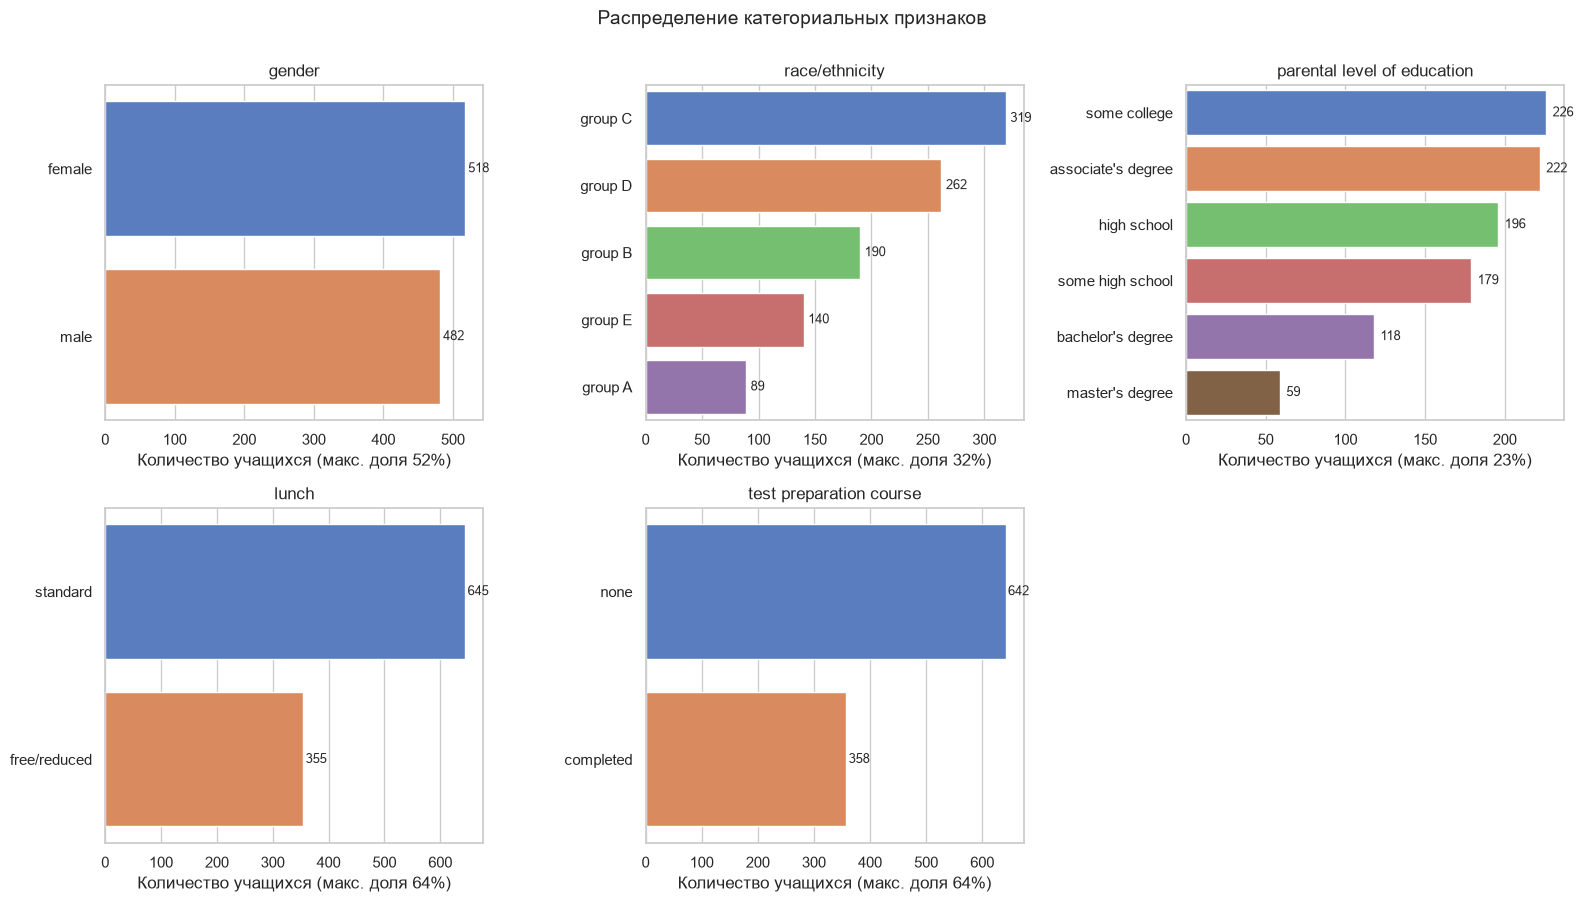

In [12]:
categorical_features = ['gender', 'race/ethnicity', 'parental level of education',
                        'lunch', 'test preparation course']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, categorical_features):
    order = data[col].value_counts().index
    sns.countplot(data=data, y=col, order=order, ax=ax, palette='muted')
    ax.set_title(f'{col}', fontsize=12)
    ax.set_xlabel('Количество учащихся')
    ax.set_ylabel('')
    for patch in ax.patches:
        ax.text(patch.get_width() + 4, patch.get_y() + patch.get_height() / 2,
                f'{int(patch.get_width())}', va='center', fontsize=9)
    # доля самой частой категории
    top_share = data[col].value_counts(normalize=True).iloc[0] * 100
    ax.set_xlabel(f'Количество учащихся (макс. доля {top_share:.0f}%)')

axes[-1].axis('off')
plt.suptitle('Распределение категориальных признаков', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

**Что видно по категориальным признакам:**

- `gender` — практически **сбалансирован**: 518 девушек против 482 юношей, перекоса нет.
- `race/ethnicity` — **заметный дисбаланс**: группа `C` встречается 319 раз, а группа `A` — всего 89, то есть разница в 3.6 раза. Самая маленькая группа будет давать менее устойчивые оценки среднего.
- `parental level of education` — распределение **неравномерное и смещено к среднему уровню**: `some college` (226), `associate's degree` (222), `high school` (196) — это основная масса; а `master's degree` всего 59 и `bachelor's degree` 118. То есть людей с высшим образованием в выборке мало, и выводы по этой категории будут шумными.
- `lunch` — **дисбаланс 645 / 355** в пользу платного питания. Это важно, потому что именно этот признак, как увидим ниже, сильнее всего связан с баллом.
- `test preparation course` — только **358 из 1000** проходили курс, остальные 642 — нет. Курс выбирают не все, и нельзя исключать, что его выбирают более мотивированные ученики (self-selection), а не что он сам по себе даёт прирост.

Ещё три «признака» — баллы по чтению и письму. Посмотрим на них как на числовые величины.

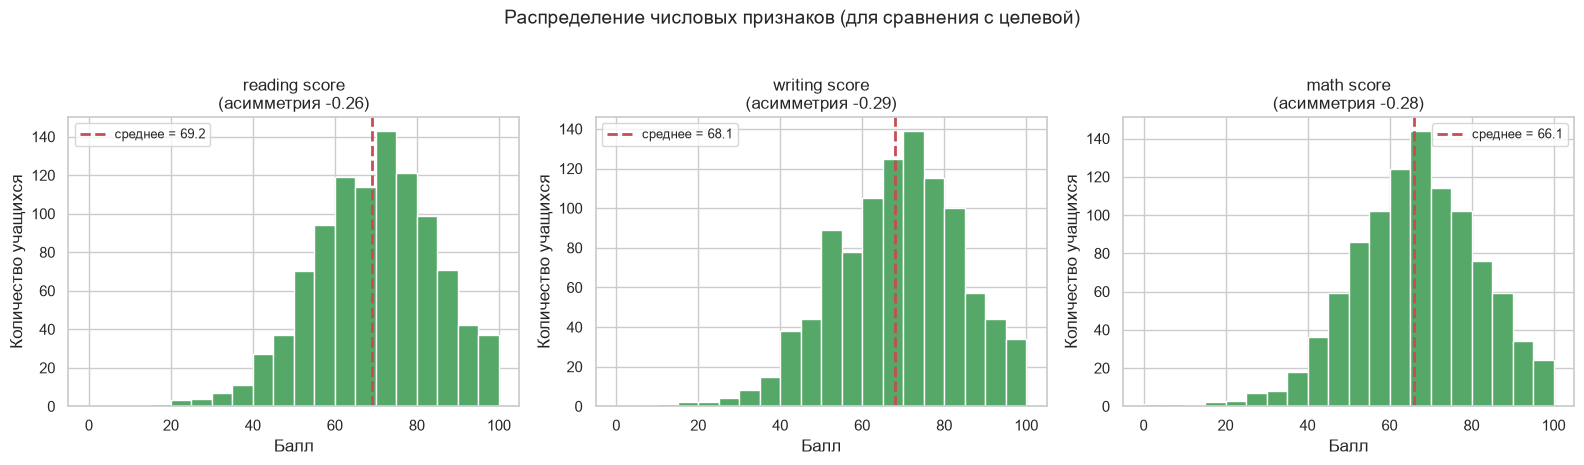

In [13]:
numeric_other = ['reading score', 'writing score']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, numeric_other + [target]):
    ax.hist(data[col], bins=range(0, 105, 5), color='#55A868', edgecolor='white')
    ax.axvline(data[col].mean(), color='#C44E52', linestyle='--', linewidth=2,
               label=f'среднее = {data[col].mean():.1f}')
    ax.set_title(f'{col}\n(асимметрия {data[col].skew():.2f})', fontsize=12)
    ax.set_xlabel('Балл')
    ax.set_ylabel('Количество учащихся')
    ax.set_xticks(range(0, 101, 20))
    ax.legend(fontsize=9)

plt.suptitle('Распределение числовых признаков (для сравнения с целевой)', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

**По числовым признакам:**

- Все три балла распределены **однотипно**: одновершинно, с небольшим левым скосом (асимметрия от -0.26 до -0.29). Это значит, что в данных нет смеси разных популяций — например, нет отдельной группы «двоечников» и отдельной «отличников» с провалом между ними.
- У `reading score` и `writing score` **левого хвоста почти нет**: минимумы 17 и 10, тогда как у математики есть выброс в 0. То есть по математике часть учеников «проваливается» заметно глубже.
- Правый край упирается в 100 (7–17 человек на максимуме), что говорит об **эффекте потолка** шкалы: часть сильных учеников, возможно, знает больше, но балл выше 100 поставить нельзя.
- Асимметрия небольшая (|skew| < 0.3), поэтому тяжёлых преобразований (логарифмирование, Бокс–Кокс) не требуется; при необходимости достаточно стандартизации.

Для сравнения наложу все три распределения на одну картинку — так проще увидеть, что математика сдвинута влево относительно остальных предметов.

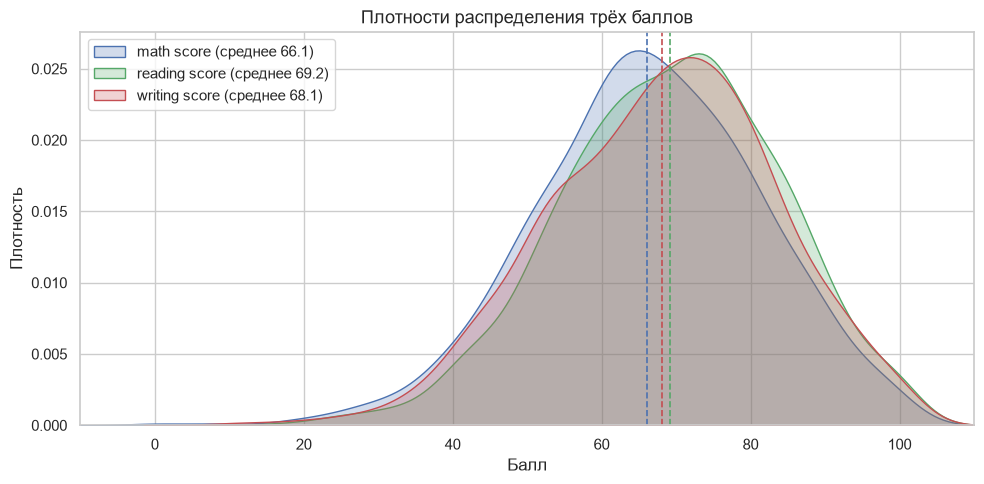

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
for col, color in zip([target, 'reading score', 'writing score'],
                      ['#4C72B0', '#55A868', '#C44E52']):
    sns.kdeplot(data[col], ax=ax, label=f'{col} (среднее {data[col].mean():.1f})',
                fill=True, alpha=0.25, color=color)
    ax.axvline(data[col].mean(), color=color, linestyle='--', linewidth=1.2)

ax.set_title('Плотности распределения трёх баллов', fontsize=13)
ax.set_xlabel('Балл')
ax.set_ylabel('Плотность')
ax.set_xlim(-10, 110)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Зависимость признаков от целевой переменной

Беру пять социально-демографических признаков и смотрю, как меняется балл по математике в разрезе каждого из них.

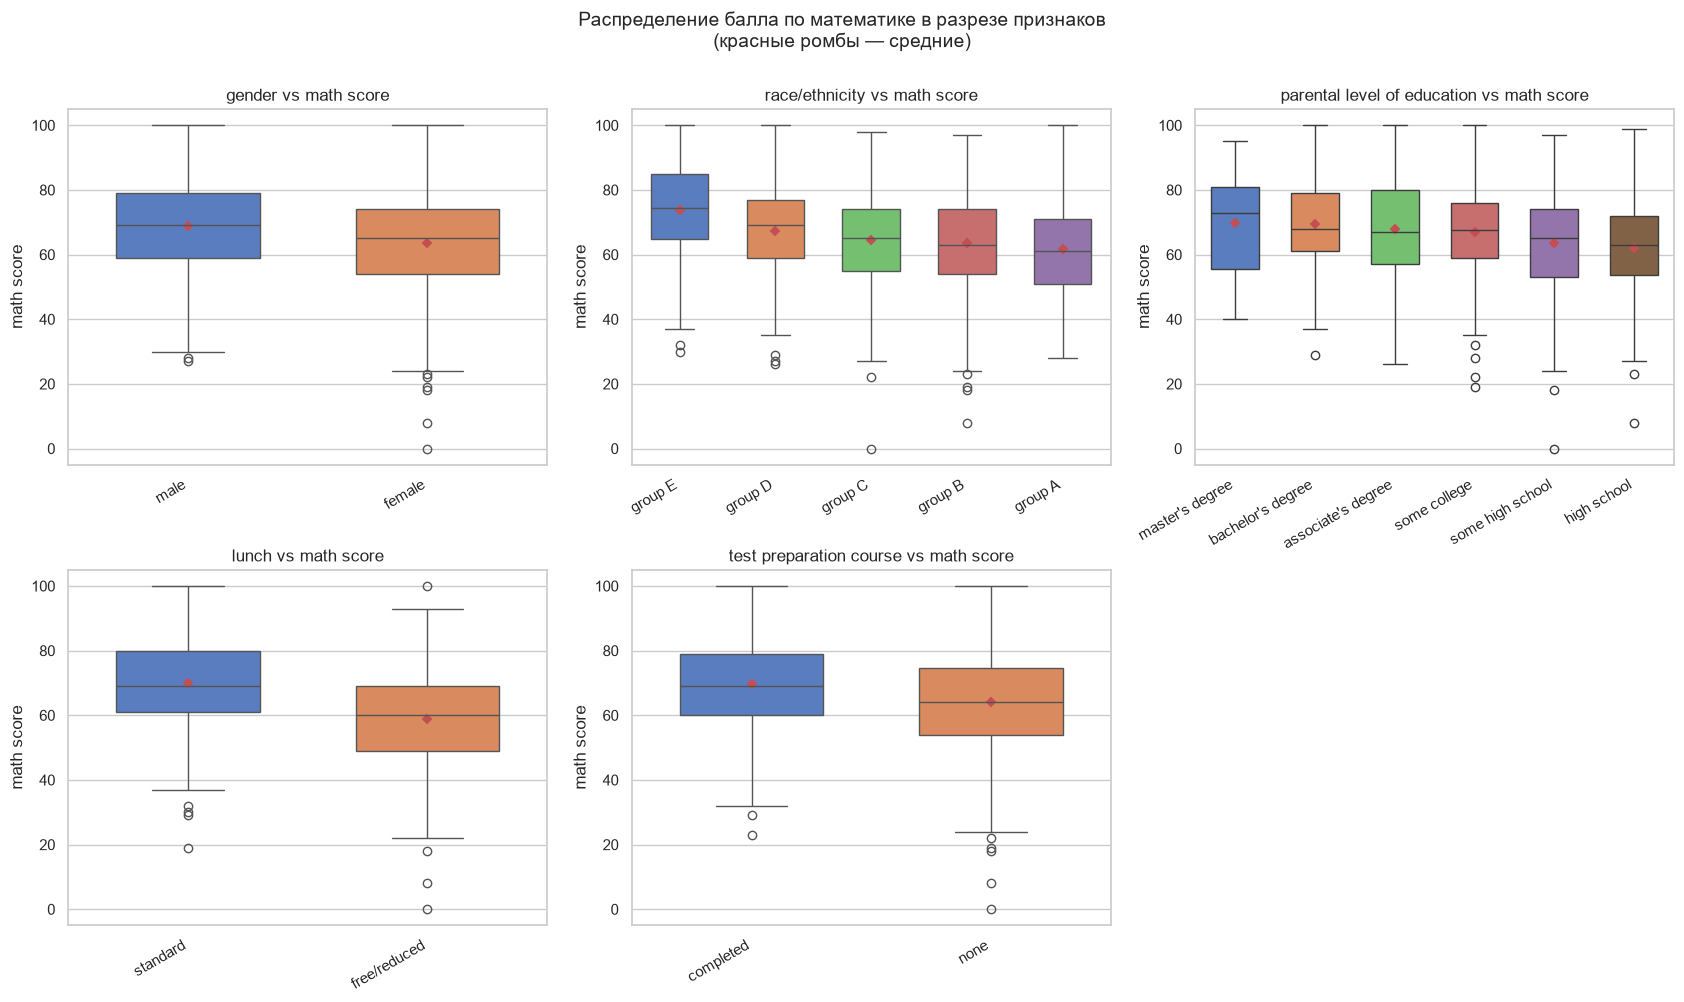

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for ax, col in zip(axes, categorical_features):
    order = data.groupby(col)[target].mean().sort_values(ascending=False).index
    sns.boxplot(data=data, x=col, y=target, order=order, ax=ax,
                palette='muted', width=0.6)
    sns.pointplot(data=data, x=col, y=target, order=order, ax=ax,
                  color='#C44E52', markers='D', linestyles='none', errorbar=None, scale=0.7)
    ax.set_title(f'{col} vs {target}', fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel('math score')
    ax.tick_params(axis='x', rotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

axes[-1].axis('off')
plt.suptitle('Распределение балла по математике в разрезе признаков\n(красные ромбы — средние)', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

In [16]:
summary = pd.DataFrame({
    'средний балл': data.groupby('gender')[target].mean(),
})
print('--- gender ---')
print(data.groupby('gender')[target].agg(['count', 'mean', 'median', 'std']).round(2))

print('\n--- lunch ---')
print(data.groupby('lunch')[target].agg(['count', 'mean', 'median', 'std']).round(2))

print('\n--- test preparation course ---')
print(data.groupby('test preparation course')[target].agg(['count', 'mean', 'median', 'std']).round(2))

print('\n--- race/ethnicity ---')
print(data.groupby('race/ethnicity')[target].agg(['count', 'mean', 'median', 'std']).round(2))

print('\n--- parental level of education ---')
print(data.groupby('parental level of education')[target].agg(['count', 'mean', 'median', 'std']).round(2))

print('\n--- разница средних между «лучшей» и «худшей» категорией, баллов ---')
for col in categorical_features:
    means = data.groupby(col)[target].mean()
    print(f'{col:32s}: {means.max() - means.min():5.2f}  ({means.idxmin()} -> {means.idxmax()})')

--- gender ---
        count   mean  median    std
gender                             
female    518  63.63    65.0  15.49
male      482  68.73    69.0  14.36

--- lunch ---
              count   mean  median    std
lunch                                    
free/reduced    355  58.92    60.0  15.16
standard        645  70.03    69.0  13.65

--- test preparation course ---
                         count   mean  median    std
test preparation course                             
completed                  358  69.70    69.0  14.44
none                       642  64.08    64.0  15.19

--- race/ethnicity ---
                count   mean  median    std
race/ethnicity                             
group A            89  61.63    61.0  14.52
group B           190  63.45    63.0  15.47
group C           319  64.46    65.0  14.85
group D           262  67.36    69.0  13.77
group E           140  73.82    74.5  15.53

--- parental level of education ---
                             count   mean  m

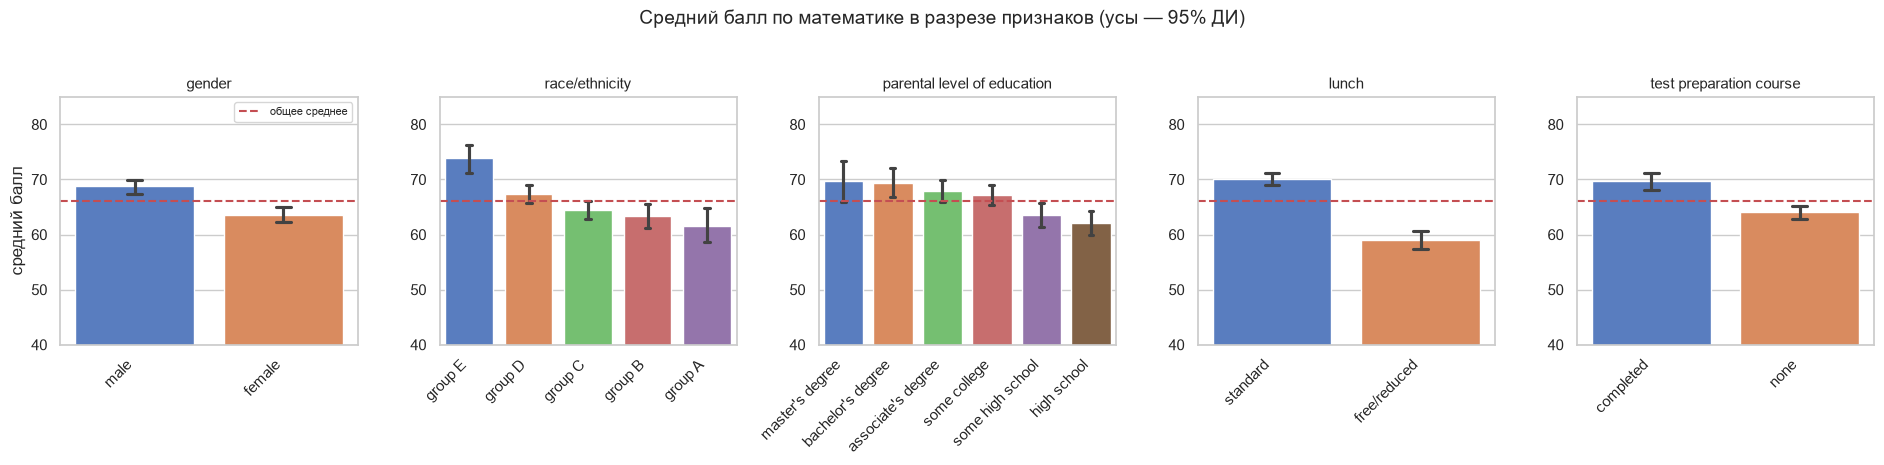

In [17]:
# те же зависимости, но более наглядно: средний балл с 95% доверительным интервалом
fig, axes = plt.subplots(1, 5, figsize=(19, 4.5))

for ax, col in zip(axes, categorical_features):
    order = data.groupby(col)[target].mean().sort_values(ascending=False).index
    sns.barplot(data=data, x=col, y=target, order=order, ax=ax,
                palette='muted', capsize=0.1, errorbar=('ci', 95))
    ax.axhline(data[target].mean(), color='#C44E52', linestyle='--', linewidth=1.5,
               label='общее среднее')
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('средний балл' if col == categorical_features[0] else '')
    ax.set_ylim(40, 85)
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

axes[0].legend(fontsize=8)
plt.suptitle('Средний балл по математике в разрезе признаков (усы — 95% ДИ)', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

**Вывод: какие переменные связаны с целевой.**

1. **`lunch` — самый сильный из категориальных признаков.** Ученики с платным питанием в среднем на **11.1 балла** выше (70.0 против 58.9). Это огромная разница — доверительные интервалы даже близко не пересекаются. Признак косвенно отражает материальное положение семьи, и связь с успеваемостью хорошо видна. Для прогноза переменная однозначно полезна.
2. **`test preparation course`** — разница **5.6 балла** в пользу прошедших курс (69.7 против 64.1). Связь есть и она статистически заметна, но **интерпретировать её как «курс помогает на 5.6 балла» нельзя**: это наблюдательные данные, ученики сами выбирали, идти ли на курс, — скорее всего его выбирают более мотивированные. Здесь классический confounding / self-selection bias.
3. **`gender`** — разница **5.1 балла** в пользу юношей по математике (68.7 против 63.6). Разброс внутри групп большой (std ~15), распределения сильно перекрываются, поэтому признак полезен, но предсказывает слабо: по полу нельзя надёжно угадать балл конкретного ученика. Любопытно, что по чтению и письму картина обратная — девушки там выше на 7 и 9 баллов.
4. **`race/ethnicity`** — монотонный градиент от группы A (61.6) к группе E (73.8), суммарный размах **12.2 балла**. Сигнал есть, но у малых групп (`A` — 89 человек) доверительные интервалы широкие, а сама переменная сильно коррелирует с `lunch`, поэтому вклад может частично дублироваться.
5. **`parental level of education`** — разброс средних **7.6 балла**, и он **не монотонный**: `master's degree` (69.8) и `bachelor's degree` (69.4) выше остальных, но `high school` (62.1) и `some high school` (63.5) идут почти вровень, а между `some college` (67.1) и `associate's degree` (67.9) разницы практически нет. То есть важен скорее факт «есть высшее образование или нет», чем число лет учёбы. Признак слабее, чем `lunch`, но не бесполезен.

Общий вывод по пункту: **все пять признаков имеют какую-то связь с целевой переменной** — ни один не оказался шумом с одинаковыми средними во всех категориях. Самые перспективные для модели — `lunch` и `test preparation course`, средний — `race/ethnicity` и `gender`, самый слабый — `parental level of education`. При этом категориальные признаки объясняют лишь часть разброса: стандартное отклонение внутри каждой категории (13–16 баллов) заметно больше разницы между категориями (5–12 баллов), так что на одних демографических данных точный прогноз не построить — понадобятся другие признаки ученика.

Теперь посмотрю на числовые признаки — баллы по чтению и письму.

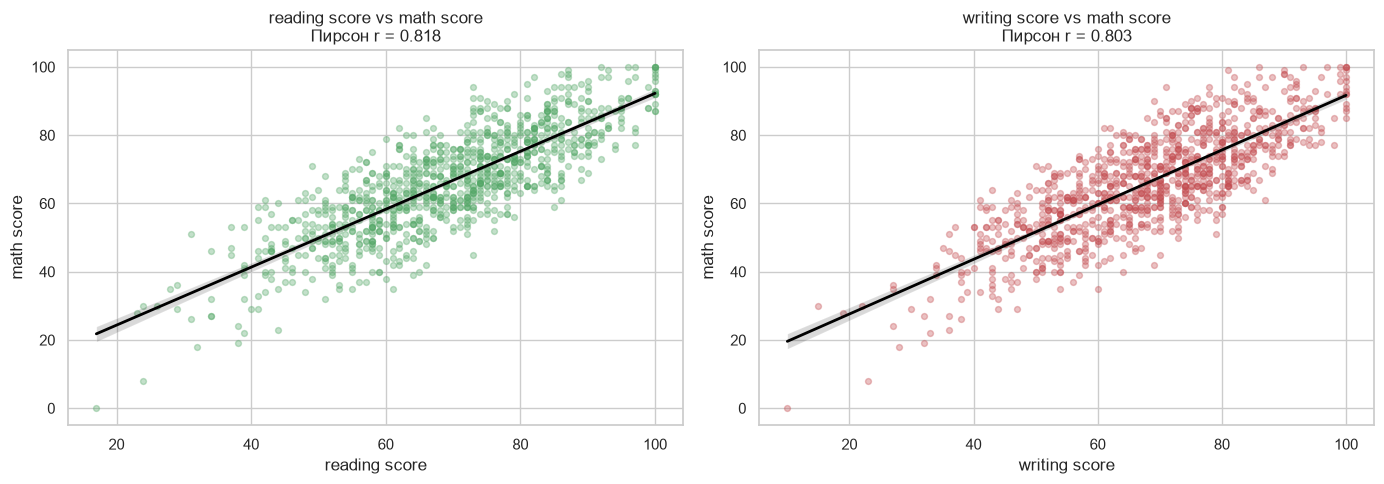

               math score  reading score  writing score
math score          1.000          0.818          0.803
reading score       0.818          1.000          0.955
writing score       0.803          0.955          1.000


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, color in zip(axes, ['reading score', 'writing score'],
                          ['#55A868', '#C44E52']):
    sns.regplot(data=data, x=col, y=target, ax=ax,
                scatter_kws={'alpha': 0.35, 's': 18, 'color': color},
                line_kws={'color': 'black', 'linewidth': 2})
    r = data[col].corr(data[target])
    ax.set_title(f'{col} vs {target}\nПирсон r = {r:.3f}', fontsize=12)
    ax.set_xlabel(col)
    ax.set_ylabel(target)

plt.tight_layout()
plt.show()

print(data[[target, 'reading score', 'writing score']].corr().round(3))

Числовые признаки связаны с целевой переменной **очень сильно**: корреляция Пирсона `0.818` с баллом по чтению и `0.803` с баллом по письму. Облако точек вытянуто вдоль прямой, разброс вокруг линии регрессии небольшой — это лучшие предикторы из всех имеющихся.

Но именно поэтому с ними нужно обращаться осторожно: это **баллы за другие экзамены того же ученика**, то есть информация из «будущего» относительно момента прогноза. В реальной системе их бы не было. Для честной оценки модели такие признаки надо исключать, иначе метрики будут отличными, а пользы ноль — классическая утечка данных.

Заодно отсюда видно, что все три балла измеряют общий фактор «успеваемость»: корреляция чтения и письма вообще `0.955`, то есть это почти одна и та же переменная.

## 9. *Extra*: две переменные одновременно против целевой

Сначала — облако точек `reading score` × `writing score`, раскрашенное по значению целевой переменной. Так видно, как балл по математике распределён в двумерном пространстве двух других баллов.

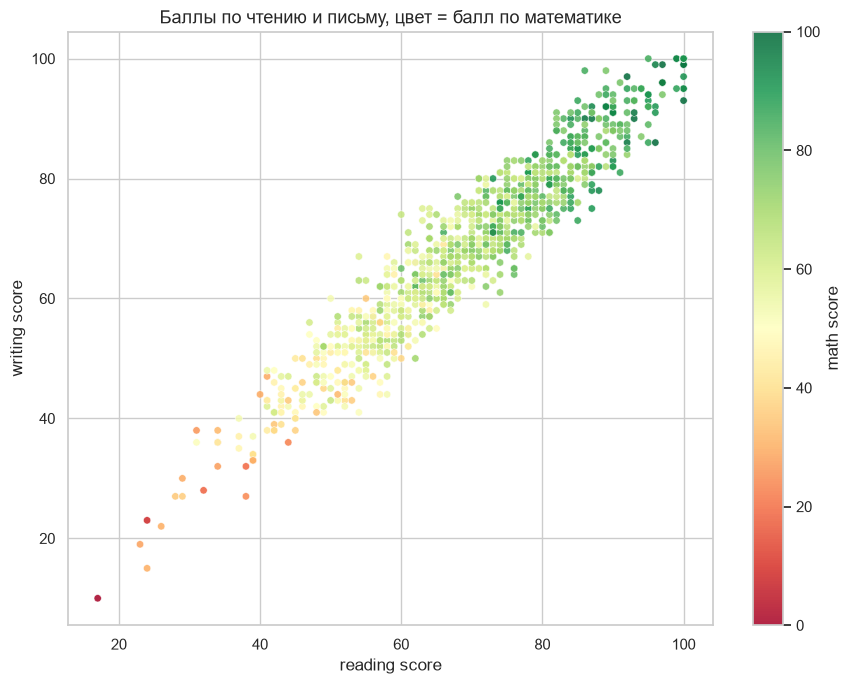

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))

scatter = ax.scatter(data['reading score'], data['writing score'],
                     c=data[target], cmap='RdYlGn', s=28, alpha=0.85,
                     edgecolors='white', linewidths=0.4)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('math score')

ax.set_title('Баллы по чтению и письму, цвет = балл по математике', fontsize=13)
ax.set_xlabel('reading score')
ax.set_ylabel('writing score')
plt.tight_layout()
plt.show()

Видна чёткая **диагональная структура**: точки ложатся вдоль линии `y ≈ x`, то есть ученики, хорошо написавшие чтение, обычно хорошо пишут и письмо. Цвет тоже меняется вдоль этой диагонали — в левом нижнем углу скапливаются красные точки (низкий балл по математике), в правом верхнем — зелёные (высокий). Значит, целевая переменная в основном определяется общей «силой» ученика, а расхождение между предметами — это уже вторичный эффект.

Интересен и разброс **поперёк** диагонали: есть ученики с высоким письмом и заметно более низкой математикой, и наоборот. Именно эти точки модель с трудом предскажет по одним лишь баллам других предметов.

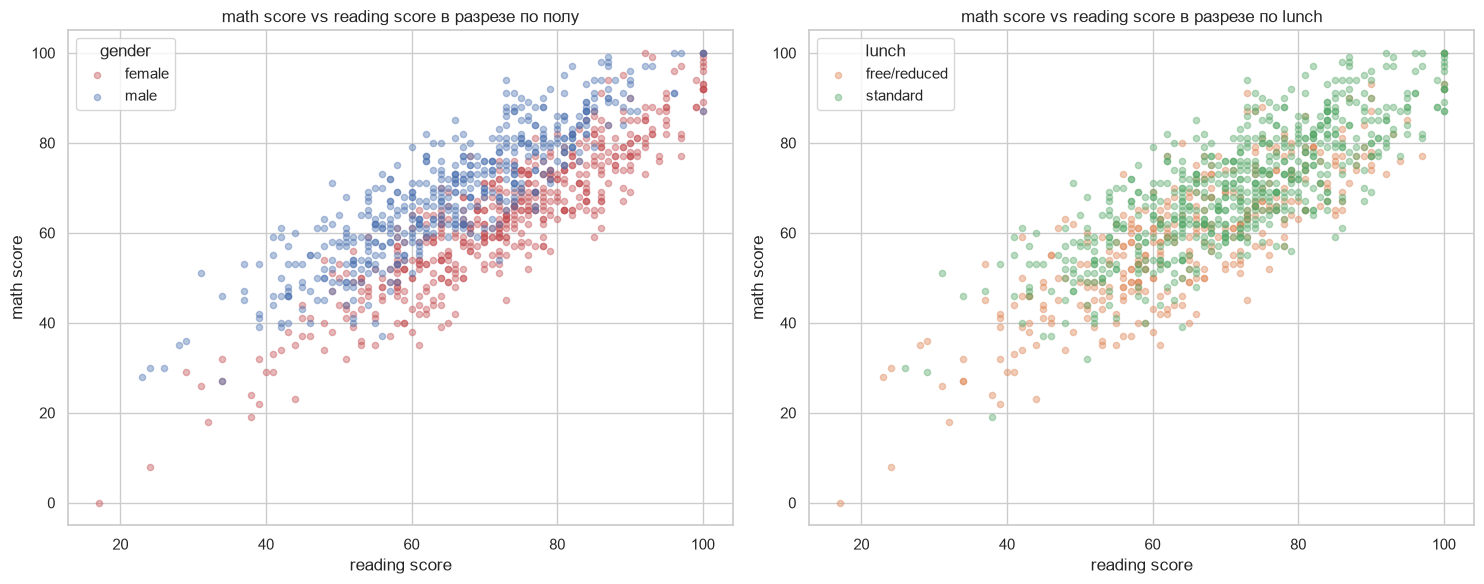

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# разрез по полу
for gender, color in zip(['female', 'male'], ['#C44E52', '#4C72B0']):
    subset = data[data['gender'] == gender]
    axes[0].scatter(subset['reading score'], subset[target],
                    alpha=0.4, s=20, label=gender, color=color)
axes[0].set_xlabel('reading score')
axes[0].set_ylabel('math score')
axes[0].set_title('math score vs reading score в разрезе по полу', fontsize=12)
axes[0].legend(title='gender')

# разрез по типу питания
for lunch, color in zip(['free/reduced', 'standard'], ['#DD8452', '#55A868']):
    subset = data[data['lunch'] == lunch]
    axes[1].scatter(subset['reading score'], subset[target],
                    alpha=0.4, s=20, label=lunch, color=color)
axes[1].set_xlabel('reading score')
axes[1].set_ylabel('math score')
axes[1].set_title('math score vs reading score в разрезе по lunch', fontsize=12)
axes[1].legend(title='lunch')

plt.tight_layout()
plt.show()

**Что даёт разрез по двум переменным.** Левое облако: девушки (красные) смещены вправо по чтению, но ниже по математике — при одинаковом балле за чтение юноша в среднем получит по математике больше. То есть линии регрессии для полов параллельны-ish, но сдвинуты: **эффект пола сохраняется и после контроля на общий уровень успеваемости**.

Правое облако: разделение по `lunch` ещё заметнее — облако `free/reduced` (оранжевое) лежит **ниже** облака `standard` (зелёное) на всём диапазоне чтения, а не только в среднем. Это значит, что связь `lunch` с математикой не объясняется тем, что эти ученики в целом слабее читают: сдвиг есть при любом уровне чтения.

Теперь то же самое, но для категориальных признаков — тепловая карта средних баллов. Беру пары `gender` × `lunch` и `test preparation course` × `lunch`.

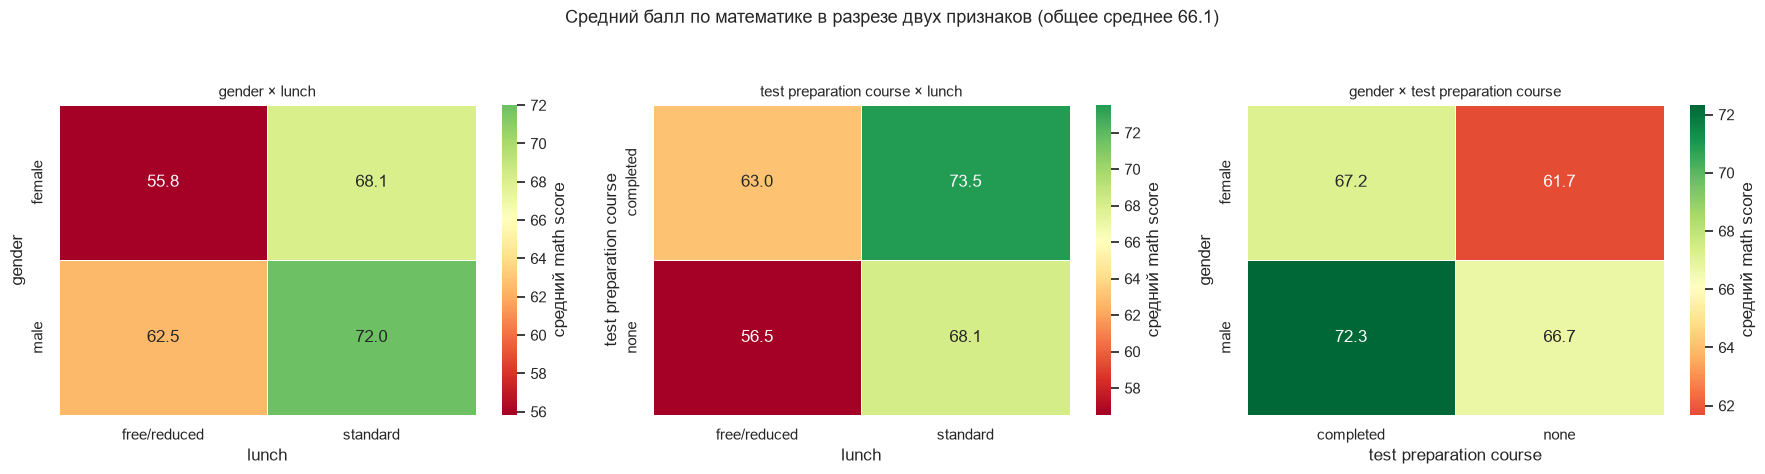

gender × lunch:
lunch   free/reduced  standard
gender                        
female          55.8      68.1
male            62.5      72.0

test preparation × lunch:
lunch                    free/reduced  standard
test preparation course                        
completed                        63.0      73.5
none                             56.5      68.1


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

pairs = [
    ('gender', 'lunch'),
    ('test preparation course', 'lunch'),
    ('gender', 'test preparation course'),
]

for ax, (row_col, col_col) in zip(axes, pairs):
    pivot = data.pivot_table(index=row_col, columns=col_col, values=target, aggfunc='mean')
    sns.heatmap(pivot, annot=True, fmt='.1f', cmap='RdYlGn', center=data[target].mean(),
                linewidths=0.5, cbar_kws={'label': 'средний math score'}, ax=ax)
    ax.set_title(f'{row_col} × {col_col}', fontsize=11)
    ax.set_xlabel(col_col)
    ax.set_ylabel(row_col)

plt.suptitle(f'Средний балл по математике в разрезе двух признаков (общее среднее {data[target].mean():.1f})', fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

print('gender × lunch:')
print(data.pivot_table(index='gender', columns='lunch', values=target, aggfunc='mean').round(1))
print('\ntest preparation × lunch:')
print(data.pivot_table(index='test preparation course', columns='lunch', values=target, aggfunc='mean').round(1))

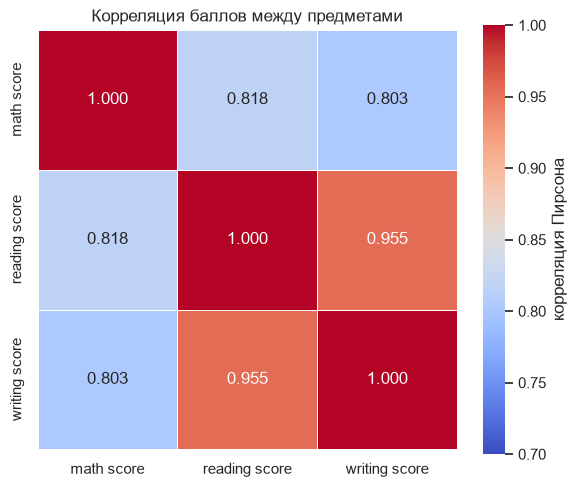

In [22]:
# тепловая карта корреляций числовых переменных
plt.figure(figsize=(6, 5))
corr = data[['math score', 'reading score', 'writing score']].corr()
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=0.7, vmax=1.0,
            linewidths=0.5, square=True, cbar_kws={'label': 'корреляция Пирсона'})
plt.title('Корреляция баллов между предметами', fontsize=12)
plt.tight_layout()
plt.show()

**Выводы по extra-части:**

- Наивысший средний балл у комбинации **«юноша + платное питание + пройденный курс»** — **76.0**, низший — у **«девушка + льготное питание + без курса»** — **52.9**. Размах между крайними ячейками — **23.1 балла**, то есть больше стандартного отклонения всей выборки (15.2). Уже по трём демографическим признакам учеников можно разнести на группы, различающиеся более чем на 20 баллов.
- Влияния **складываются, а не дублируют друг друга**: внутри каждого уровня `lunch` прохождение курса даёт близкий прирост — 52.9 → 60.8 у девушек с льготным питанием и 66.5 → 71.1 у девушек с платным (то есть **+5.5…+7.9 балла**, в среднем около 6). С полом та же картина: при платном питании разрыв между юношами и девушками 76.0 − 71.1 = 4.9, при льготном 65.6 − 60.8 = 4.8 — практически одинаковый. Значит, признаки работают в основном **аддитивно, без сильного взаимодействия**, и все три стоит включать в модель.
- Тепловая карта корреляций подтверждает: баллы по трём предметам измеряют одну латентную «успеваемость» (r = 0.80–0.96), поэтому `reading` и `writing` — это фактически два измерения одного и того же. Для модели достаточно было бы одного из них.

## Итоговые выводы по EDA

1. **Данные чистые:** 1000 строк, 8 колонок, пропусков и дубликатов нет, всё приведено к нужным типам. Предобработка практически не требуется — только кодирование категориальных признаков (one-hot или target encoding) и стандартизация для моделей, чувствительных к масштабу.
2. **Целевая переменная** `math score` — ограниченный целочисленный балл `[0; 100]`, 81 уникальное значение, распределение унимодальное с небольшим левым скосом, центр около 66, разброс 15.2. Выраженного дисбаланса нет, но хвосты (`<= 40` и `>= 90`) представлены слабо, а один ученик с нулём — потенциальный выброс.
3. **Связь с целевой подтверждена для всех пяти категориальных признаков**, сильнее всего для `lunch` (11.1 балла разницы). Но разброс внутри категорий в 2–3 раза превышает разницу между ними — на одной демографии точный прогноз не выйдет.
4. **Баллы по чтению и письму** — сильнейшие предикторы (r = 0.80–0.82) и одновременно главный риск утечки данных. Для честной постановки задачи их нужно выделять в отдельный сценарий.
5. **Следующие шаги:** кодирование категориальных признаков, отбор признаков, обучение базовой регрессии (линейная / гребневая) с кросс-валидацией, оценка по MAE/RMSE и сравнение с константным предсказанием. Стоит также проверить нелинейные модели (градиентный бустинг, случайный лес) — возможно, взаимодействия признаков дадут прирост, которого не видно в одномерном анализе.